# Étude exploratoire et inférence statistique du catalogue — MeloWave (Mission 1)
**Auteur :** Lucas PIANEZZI  
**Rôle :** Data Analyst  
**Destinataire :** Camille Roussel (Directrice des études musicales)  
**Mission :** Audit qualité, profiling audio et validation statistique des hypothèses éditoriales.

## Sommaire
1. Audit de la qualité des données et nettoyage
   - 1.1. Dictionnaire des données & Signification des variables
   - 1.2. État des lieux des valeurs manquantes et types
   - 1.3. Audit et traitement des doublons : stricts vs doublons de track_id
   - 1.4. Transformation de la durée (duration_ms vers duration_s)
2. Description du catalogue et profiling audio
   - 2.1. Statistiques descriptives globales et point de vigilance sur la popularité nulle
   - 2.2. Analyse de la forme des distributions (Skewness & Kurtosis) et visualisations
   - 2.3. Interprétation des distributions
   - 2.4. Classements clés du catalogue et traitement des featurings
   - 2.5. Comparaison du profil audio moyen de genres contrastés (Radar Chart)
   - 2.6. Synthèse et gestion des valeurs aberrantes (IQR)

3. Tests statistiques d'hypothèses
   - 3.1. Relations entre caractéristiques audio
   - 3.2. Différence de popularité selon le genre
   - 3.3. Dépendance du contenu explicite selon le genre

4. Synthèse et recommandations pour le comité éditorial

In [1]:
#importation des librairies
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configuration de l'affichage graphique
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Options pandas pour voir toutes les colonnes
pd.set_option("display.max_columns", None)

print("Librairies importées avec succès !")

Librairies importées avec succès !


## 1. Audit de la qualité des données et nettoyage
Chargement des données brutes pour vérifier la présence de valeurs nulles, de doublons et le type de chaque colonne.

In [2]:
#Lecture du fichier de données
df = pd.read_csv("spotify-tracks-dataset-detailed.csv")

#Affichage des dimensions et des 5 premières lignes
print(f"Nombre de lignes : {df.shape[0]}, Nombre de colonnes : {df.shape[1]}")
df.head()

Nombre de lignes : 114000, Nombre de colonnes : 20


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


## Étape 1 : Audit qualité, nettoyage et préparation des données

### 1.1. Dictionnaire des données & Signification des variables
Le jeu de données contient initialement 114 000 lignes et 20 colonnes. Voici le dictionnaire des variables de travail :

#### Variables d'identification et métadonnées
- **track_id** : identifiant unique Spotify attribué au morceau.
- **artists** : nom du ou des artistes interprètes.
- **album_name** : nom de l'album sur lequel figure le morceau.
- **track_name** : titre de la piste.
- **track_genre** : genre musical associé à la ligne (114 genres distincts dans la base).
- **Explicit** : booléen (True/False) indiquant si le morceau contient des paroles explicites (grossièretés, etc.), signalé par les maisons de disques.
- **Popularity** : score de 0 à 100 calculé par Spotify, basé sur le nombre d'écoutes récentes (les écoutes récentes pèsent plus que les anciennes).
- **Duration** (duration_ms) : durée initiale du morceau en millisecondes.

#### Caractéristiques audio
- **Danceability** (0 à 1) : à quel point un morceau donne envie de danser, est basé sur un mix de tempo, a une stabilité rythmique, la force du beat, la régularité.
- **Energy** (0 à 1) : intensité perçue (morceau rapide, bruyant, "punchy" = beaucoup d'énergie).
- **Loudness** : volume moyen en dB (généralement entre -60 et 0 dB).
- **Acousticness** (0 à 1) : confiance sur le fait que le morceau est acoustique (pas électronique/produit).
- **Valence** (0 à 1) : positivité musicale, dimension émotionnelle, c'est-à-dire qu'un morceau qui sonne comme joyeux voire euphorisant serait proche de 1 alors qu'un morceau évoquant la tristesse ou encore la colère serait proche de 0.
- **Tempo** : tempo global en BPM (battements par minute).
- **Speechiness** (0 à 1) : présence de paroles parlées (valeurs élevées pour du podcast, rap, slam).
- **Instrumentalness** (0 à 1) : prédit si un morceau ne contient pas de voix (proche de 1 pour du classique/ambient).
- **Liveness** (0 à 1) : détecte la présence d'un public dans l'enregistrement (probabilité de live).

#### Métadonnées de solfège
- **key** : tonalité principale estimée selon le système standard Pitch Class (0 = Do/C, 1 = Do♯/C♯, 2 = Ré/D, 3 = Ré♯/D♯, 4 = Mi/E, 5 = Fa/F, 6 = Fa♯/F♯, 7 = Sol/G, 8 = Sol♯/G♯, 9 = La/A, 10 = La♯/A♯, 11 = Si/B, -1 = non détectée).
- **mode** : modalité musicale du morceau issue de l'API Spotify (1 = Majeur, 0 = Mineur).
- **time_signature** : combien de temps composent chaque mesure musicale.

### 1.2. État des lieux des valeurs manquantes et types
Avant toute analyse, nous vérifions l'intégrité technique des données : types de variables et recensement des cellules vides (`NaN`).

In [3]:
# Relevé des types et calcul du nombre et pourcentage de valeurs manquantes
audit_na = pd.DataFrame({
    'Type': df.dtypes,
    'Valeurs Manquantes': df.isnull().sum(),
    '% Manquant': (df.isnull().sum() / len(df) * 100).round(4)
})

# Filtrage pour afficher les colonnes concernées ou confirmer l'absence
display(audit_na[audit_na['Valeurs Manquantes'] > 0])

,Type,Valeurs Manquantes,% Manquant
artists,object,1,0.0009
album_name,object,1,0.0009
track_name,object,1,0.0009


> **Décision pour les valeurs manquantes :**  
> Les valeurs manquantes sont situées uniquement sur des champs texte comme `artists`, `album_name` ou `track_name`. Elles représentent une fraction minime du catalogue 
>(< 0,001 %). Leur suppression n'introduit aucun biais de sélection mesurable sur les analyses acoustiques. Nous procédons à leur suppression.

In [4]:
# Traitement des NaN avec suivi rigoureux de la volumétrie
lignes_initiales = len(df)

df_clean = df.dropna().copy()
lignes_apres_na = len(df_clean)
suppr_na = lignes_initiales - lignes_apres_na

print(f"Lignes initiales : {lignes_initiales}")
print(f"Lignes supprimées suite aux NaN : {suppr_na}")
print(f"Lignes restantes : {lignes_apres_na}")

Lignes initiales : 114000
Lignes supprimées suite aux NaN : 1
Lignes restantes : 113999


### 1.3. Audit et traitement des doublons : stricts vs doublons de `track_id`
Nous séparons strictement deux réalités distinctes :
1. **Doublons stricts :** lignes identiques sur l'intégralité des 20 colonnes (doublon à supprimer)
2. **Doublons de `track_id` :** un même morceau rattaché à plusieurs genres (`track_genre`). Un titre peut être à la fois *pop* et *dance*

In [5]:
# Comptage des doublons stricts en comparant les lignes
nb_doublons_stricts = df_clean.duplicated().sum()

# Détection des doublons sur track_id
nb_doublons_track_id = df_clean.duplicated(subset=['track_id']).sum()
nb_morceaux_uniques = df_clean['track_id'].nunique()

print(f"Nombre de doublons stricts : {nb_doublons_stricts}")
print(f"Nombre de morceaux uniques réels : {nb_morceaux_uniques}")
print(f"Nombre d'enregistrements excédentaires liés au multi-genre : {nb_doublons_track_id}")

Nombre de doublons stricts : 450
Nombre de morceaux uniques réels : 89740
Nombre d'enregistrements excédentaires liés au multi-genre : 24259


In [6]:
# Suppression des doublons stricts
lignes_avant_dedup = len(df_clean)

df_clean = df_clean.drop_duplicates().copy()
lignes_apres_dedup = len(df_clean)
suppr_stricts = lignes_avant_dedup - lignes_apres_dedup

print(f"Lignes avant déduplication stricte : {lignes_avant_dedup}")
print(f"Doublons stricts supprimés : {suppr_stricts}")
print(f"Lignes conservées : {lignes_apres_dedup}")

Lignes avant déduplication stricte : 113999
Doublons stricts supprimés : 450
Lignes conservées : 113549


> **Justification et arbitrage de gestion des morceaux multi-genre :**  
> Ne garder qu'un genre par morceau crée un choix arbitraire (ex. classer un titre en pop plutôt qu'en électro fausse les stats par genre).  
> Garder toutes les occurrences fausse l'analyse audio globale en surévaluant les titres multi-étiquetés.
>  
> **Nous créons donc deux jeux de données :**
> - **`df_genres`** : conserve l'ensemble des associations morceau-genre nettoyées ($N = 113\,549$).
> - **`df_tracks`** : dédupliqué strictement sur l'identifiant unique `track_id` ($N = 89\,740$).

In [7]:
#Création des deux DataFrames

#df_genres conserves tous les liens multi-genre
df_genres = df_clean.copy()

#df_tracks a qu'une ligne par morceau
df_tracks = df_clean.drop_duplicates(subset=['track_id']).copy()

print(f"Catalogue multi-genres (df_genres) : {df_genres.shape[0]} lignes")
print(f"Catalogue morceaux uniques (df_tracks) : {df_tracks.shape[0]} lignes")


Catalogue multi-genres (df_genres) : 113549 lignes
Catalogue morceaux uniques (df_tracks) : 89740 lignes


### 1.4. Transformation de la durée (`duration_ms` vers `duration_s`)
Pour rendre les temps de lecture plus intuitifs, nous convertissons la durée de millisecondes en secondes :
$$\text{duration\_s} = \frac{\text{duration\_ms}}{1000}$$

In [8]:
# Application de la transformation sur les deux tables
for d in [df_genres, df_tracks]:
    d['duration_s'] = (d['duration_ms'] / 1000).round(2)
    d.drop(columns=['duration_ms'], inplace=True)

# Contrôle visuel sur les 3 premières lignes
display(df_tracks[['track_id', 'track_name', 'artists', 'duration_s']].head(3))

,track_id,track_name,artists,duration_s
0,5SuOikwiRyPMVoIQDJUgSV,Comedy,Gen Hoshino,230.67
1,4qPNDBW1i3p13qLCt0Ki3A,Ghost - Acoustic,Ben Woodward,149.61
2,1iJBSr7s7jYXzM8EGcbK5b,To Begin Again,Ingrid Michaelson;ZAYN,210.83


## Étape 2 : Description du catalogue

Dans cette partie, nous analysons la discographie globale de MeloWave à l'aide du jeu de données `df_tracks`. 
L'objectif est d'établir un état des lieux complet : dispersion, forme des distributions, classements clés et profils types par genre.

### 2.1. Statistiques descriptives globales et point de vigilance sur la popularité nulle
Nous procédons à une analyse différentes entre les variables numériques et les variables textuelles.

In [9]:
# Variables numériques
variables_num = [
    'popularity', 'duration_s', 'danceability', 'energy', 
    'loudness', 'speechiness', 'acousticness', 'instrumentalness', 
    'liveness', 'valence', 'tempo'
]

display(df_tracks[variables_num].describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']])

# Variables catégorielles
variables_cat = ['artists', 'album_name', 'track_name', 'explicit']
display(df_tracks[variables_cat].describe())

#count : nombre de valeurs non nulles
#unique : nombre d'éléments distincts
#top : valeur la plus fréquente 
#freq : fréquence d'apparition de ce mode (top)

,mean,std,min,25%,50%,75%,max
popularity,33.198808,20.580640,0.000,19.00000,33.000000,49.000000,100.000
duration_s,229.144517,112.945802,8.590,173.04000,213.295000,264.290000,5237.300
danceability,0.562166,0.176692,0.000,0.45000,0.576000,0.692000,0.985
energy,0.634458,0.256606,0.000,0.45700,0.676000,0.853000,1.000
loudness,-8.498994,5.221518,-49.531,-10.32225,-7.185000,-5.108000,4.532
speechiness,0.087442,0.113278,0.000,0.03600,0.048900,0.085900,0.965
acousticness,0.328285,0.338321,0.000,0.01710,0.188000,0.625000,0.996
instrumentalness,0.173415,0.323849,0.000,0.00000,0.000058,0.097625,1.000
liveness,0.216971,0.194885,0.000,0.09820,0.132000,0.279000,1.000
valence,0.469474,0.262864,0.000,0.24900,0.457000,0.682000,0.995


,artists,album_name,track_name,explicit
count,89740,89740,89740,89740
unique,31437,46589,73608,2
top,George Jones,The Complete Hank Williams,Rockin' Around The Christmas Tree,False
freq,260,110,48,82036


In [10]:
# Quantification des morceaux avec popularité = 0
nb_zero_pop = (df_tracks['popularity'] == 0).sum()
pct_zero_pop = (nb_zero_pop / len(df_tracks)) * 100

print(f"Nombre de morceaux avec popularité = 0 : {nb_zero_pop}")
print(f"Proportion dans le catalogue : {pct_zero_pop:.2f}%")

Nombre de morceaux avec popularité = 0 : 9447
Proportion dans le catalogue : 10.53%


> **Constat (Popularité nulle) :**  
> 9 447 morceaux présentent un score de popularité strictement égal à 0, soit 10,53 % du catalogue.  
> - **Origine :** L'algorithme Spotify évalue la popularité sur les écoutes récentes. Un score nul ne signifie pas forcément une absence totale d'intérêt, mais indique des pistes dormantes peut-être issues de fin de catalogue.
> - **Conséquence :** Ces zéros forment un pic isolé à gauche, séparé du reste des morceaux. L'asymétrie reste proche de 0, mais ce pic suffit à rendre la distribution non normale.

### 2.2. Analyse de la forme des distributions (Skewness & Kurtosis) et visualisations

Pour évaluer la forme des distributions de nos variables avant les tests d'inférence, nous mesurons deux coefficients : ces deux indicateurs mathématiques servent à visualiser à quoi point les variable s'éloignent ou non d'une courbe gaussienne.
- **Asymétrie (*Skewness*) :** 
  - Proche de 0 : distribution gaussienne.
  - $> 0$ (asymétrie positive / étalement à droite) : concentration sur les valeurs faibles avec une queue vers les valeurs élevées.
  - $< 0$ (asymétrie négative / étalement à gauche) : concentration sur les valeurs élevées avec une queue vers les valeurs faibles.
- **Aplatissement (*Kurtosis*) :** 
  - Proche de 0 : aplatissement similaire à une loi normale.
  - $> 0$ (leptocurtique) : pic aigu au centre et queues de distribution épaisses (présence de valeurs extrêmes).
  - $< 0$ (platycurtique) : courbe aplatie avec peu de valeurs extrêmes.

In [11]:
# Calcul du skewness et kurtosis pour les variables numériques
stats_forme = []

for col in variables_num:
    skew_val = df_tracks[col].skew()
    kurt_val = df_tracks[col].kurtosis()
    stats_forme.append({
        'Variable': col,
        'Skewness': round(skew_val, 3),
        'Kurtosis': round(kurt_val, 3),
        'Tendance asymétrie': 'Droite (queue à droite)' if skew_val > 0.5 else ('Gauche (queue à gauche)' if skew_val < -0.5 else 'Symétrique')
    })

df_forme = pd.DataFrame(stats_forme)
display(df_forme)

,Variable,Skewness,Kurtosis,Tendance asymétrie
0,popularity,0.071,-0.771,Symétrique
1,duration_s,11.073,331.980,Droite (queue à droite)
2,danceability,-0.398,-0.194,Symétrique
3,energy,-0.560,-0.608,Gauche (queue à gauche)
4,loudness,-1.960,5.470,Gauche (queue à gauche)
5,speechiness,4.546,26.567,Droite (queue à droite)
6,acousticness,0.656,-1.066,Droite (queue à droite)
7,instrumentalness,1.564,0.680,Droite (queue à droite)
8,liveness,2.062,4.075,Droite (queue à droite)
9,valence,0.128,-1.047,Symétrique


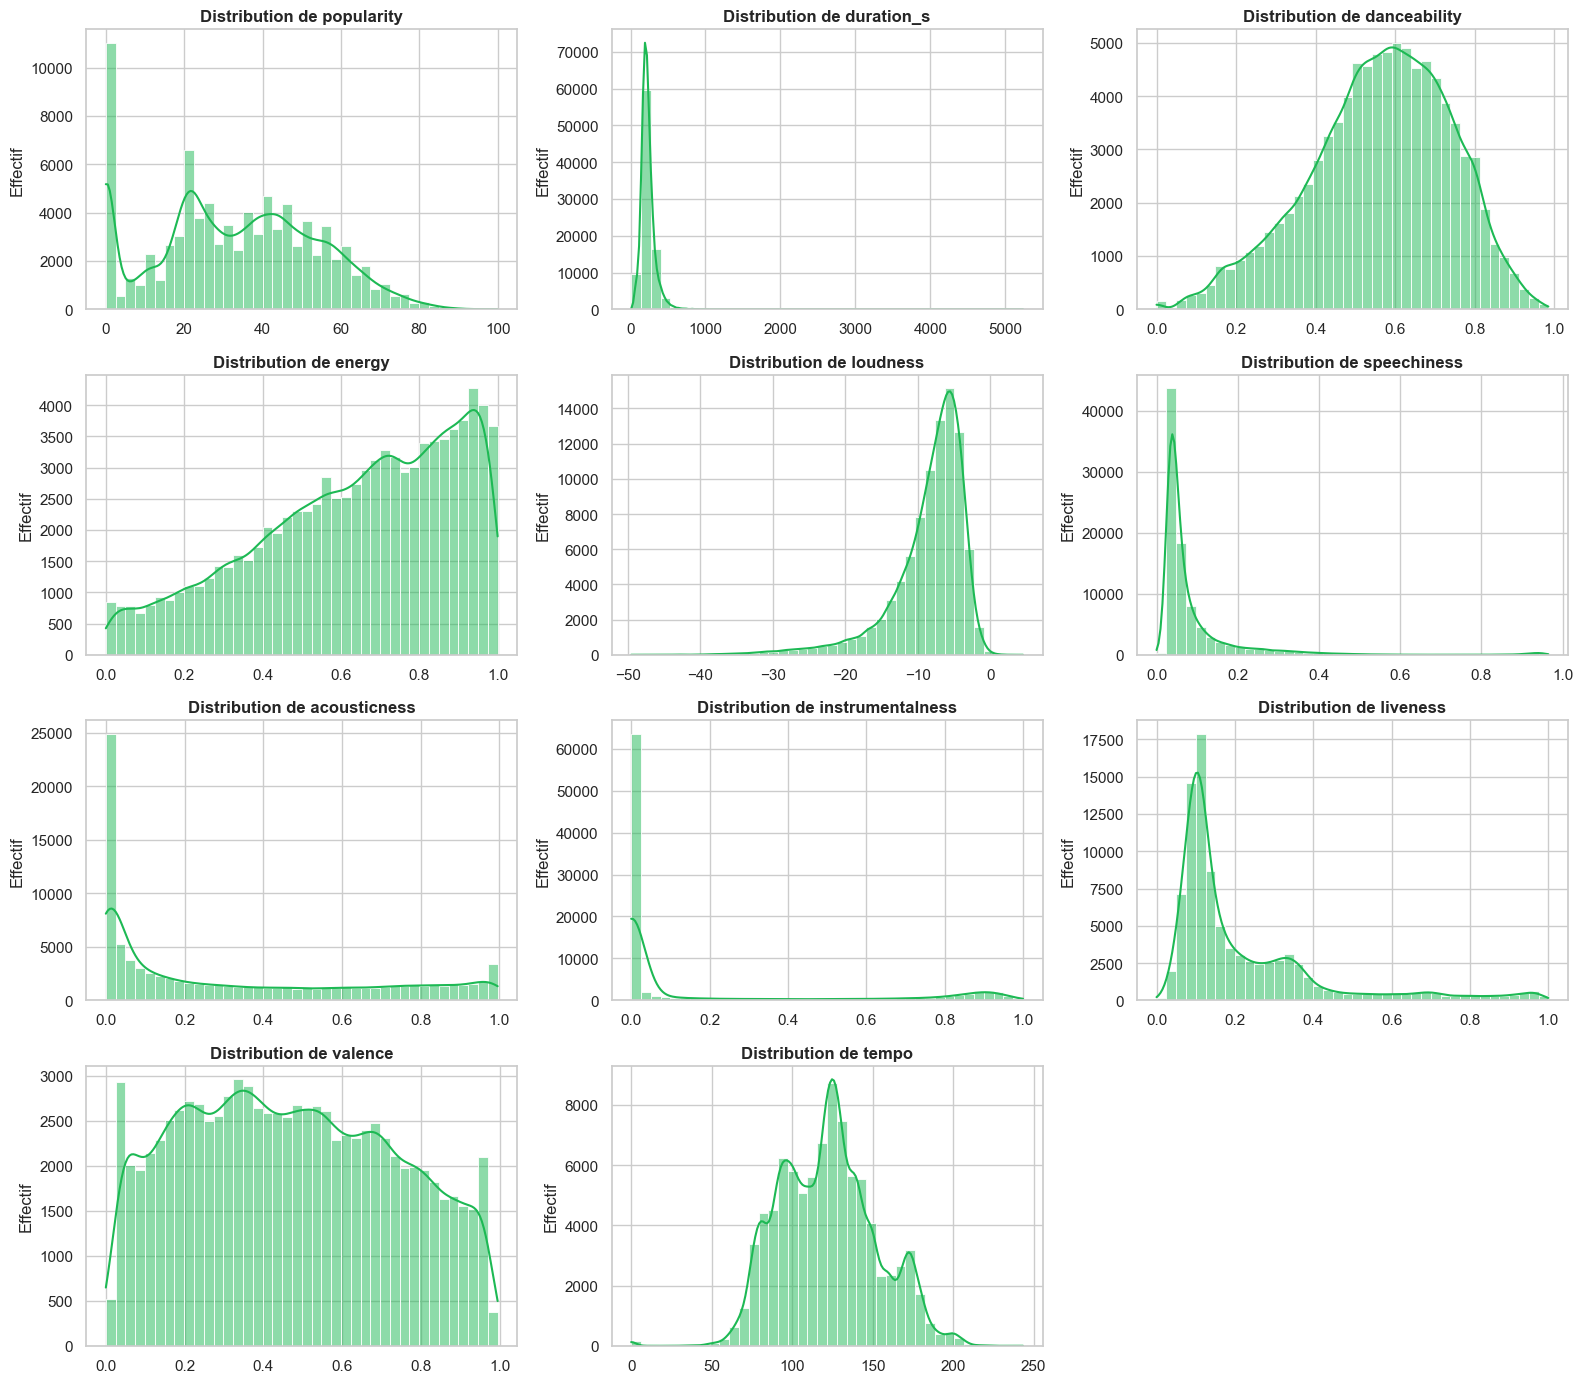

In [12]:
# Visualisation des distributions (Histogrammes)
fig, axes = plt.subplots(4, 3, figsize=(16, 14))
axes = axes.flatten()

for i, col in enumerate(variables_num):
    sns.histplot(df_tracks[col], kde=True, ax=axes[i], bins=40, color='#1DB954')
    axes[i].set_title(f"Distribution de {col}", fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Effectif')

# Masquage de la dernière case vide (11 variables pour 12 cases)
for j in range(len(variables_num), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

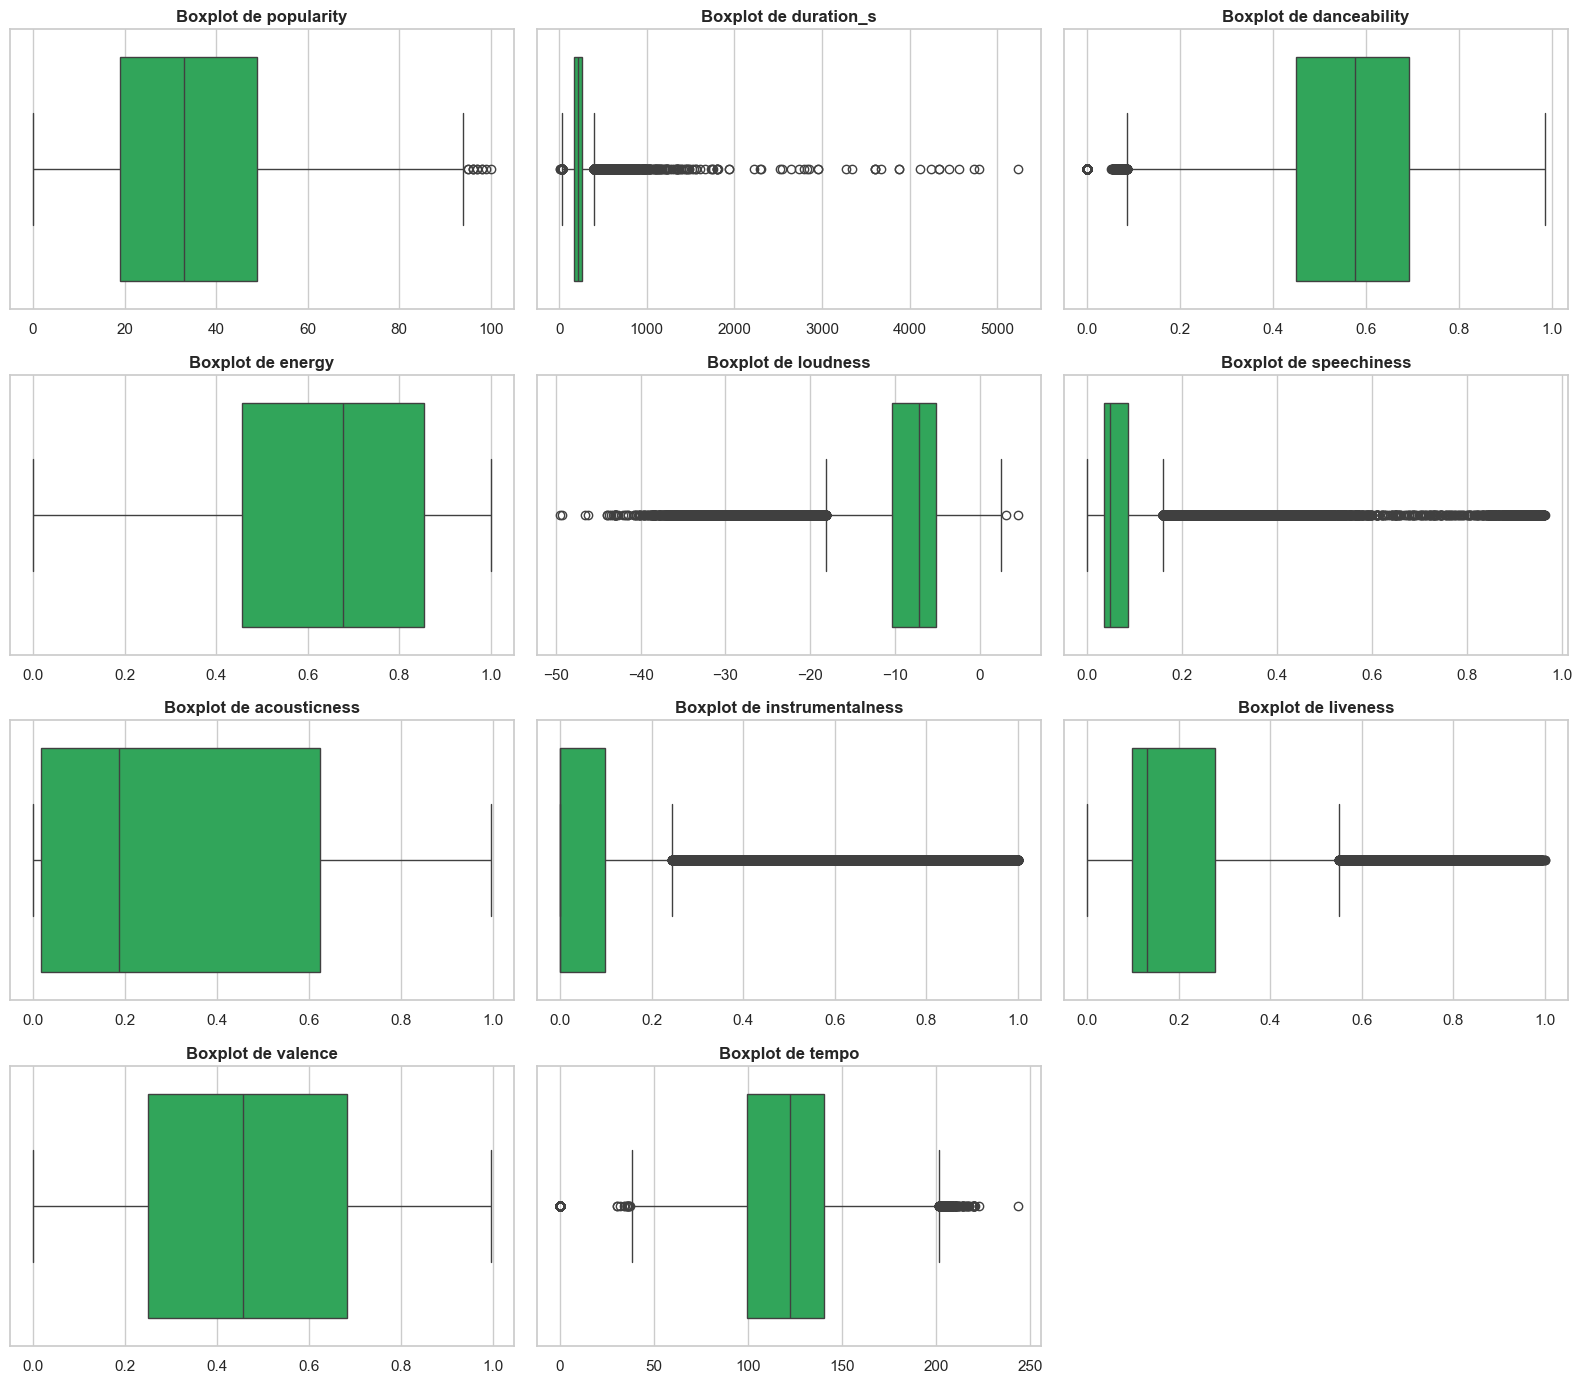

In [13]:
# Grille de boîtes à moustaches (Boxplots) pour observer la dispersion et les valeurs extrêmes
fig, axes = plt.subplots(4, 3, figsize=(16, 14))
axes = axes.flatten()

for i, col in enumerate(variables_num):
    sns.boxplot(x=df_tracks[col], ax=axes[i], color='#1DB954')
    axes[i].set_title(f"Boxplot de {col}", fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')

# Masquer la case vide
for j in range(len(variables_num), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### 2.3. Interprétation des distributions

L'analyse des coefficients (*Skewness*, *Kurtosis*) et des graphiques met en évidence plusieurs constats :

1. **Non-normalité généralisée des variables :**
   - Aucune variable audio ne suit rigoureusement une loi normale.
   - Les variables acoustiques comme `speechiness`, `liveness` et `instrumentalness` présentent des distributions fortement étalées à droite (*skewness* positif élevé), signant un catalogue dominé par des formats musicaux standards sans public, sans voix exclusive et avec du chant.

2. **Valeurs extrêmes et variabilité technique :**
   - La durée (`duration_s`) et le volume (`loudness`) présentent un kurtosis leptocurtique très marqué (kurtosis de 331,98 pour la durée). Cela confirme la présence de pistes atypiques (titres de plus d'une heure ou interludes de quelques secondes).

3. **Conséquence directe pour les tests statistiques :**
   - En raison de l'asymétrie et de l'absence de normalité, l'utilisation de tests paramétriques classiques (qui supposent une distribution gaussienne, comme le test de Pearson ou l'ANOVA) devra être rigoureusement évaluée au profit de tests non paramétriques (Spearman, Kruskal-Wallis).

### 2.4. Classements clés du catalogue et traitement des featurings

Pour identifier les moteurs d'écoute, nous établissons trois palmarès :
1. **Les titres les plus populaires du catalogue.**
2. **Les artistes les plus représentés en volume** (après éclatement des collaborations)
3. **Les artistes les plus populaires en moyenne**, en appliquant un filtre d'activité minimale (au moins 5 ou 10 morceaux) pour neutraliser le biais des artistes avec un seul morceau ayant obtenu un buzz éphémère.

In [14]:
# Classement des morceaux les plus populaires
top_tracks = df_tracks[['track_name', 'artists', 'popularity', 'duration_s']]\
    .sort_values(by='popularity', ascending=False)\
    .drop_duplicates(subset=['track_name', 'artists'])\
    .head(10)

display(top_tracks.reset_index(drop=True))

,track_name,artists,popularity,duration_s
0,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,100,156.94
1,"Quevedo: Bzrp Music Sessions, Vol. 52",Bizarrap;Quevedo,99,198.94
2,La Bachata,Manuel Turizo,98,162.64
3,I'm Good (Blue),David Guetta;Bebe Rexha,98,175.24
4,Me Porto Bonito,Bad Bunny;Chencho Corleone,97,178.57
5,Tití Me Preguntó,Bad Bunny,97,243.72
6,I Ain't Worried,OneRepublic,96,148.49
7,Under The Influence,Chris Brown,96,184.61
8,Efecto,Bad Bunny,96,213.06
9,As It Was,Harry Styles,95,167.30


In [15]:
# Éclatement des featurings (séparateur ';')
# On crée une table temporaire reliant chaque artiste individuel à ses morceaux uniques
df_artists_exploded = df_tracks[['track_id', 'artists', 'popularity']].copy()

# Séparation sur le point-virgule et éclatement des lignes
df_artists_exploded['artist_individual'] = df_artists_exploded['artists'].str.split(';')
df_artists_exploded = df_artists_exploded.explode('artist_individual')

# Nettoyage des espaces éventuels autour des noms
df_artists_exploded['artist_individual'] = df_artists_exploded['artist_individual'].str.strip()

print(f"Nombre d'associations artiste-morceau après éclatement : {len(df_artists_exploded)}")
print(f"Nombre d'artistes distincts uniques : {df_artists_exploded['artist_individual'].nunique()}")

Nombre d'associations artiste-morceau après éclatement : 123424
Nombre d'artistes distincts uniques : 29858


In [16]:
# Classement des artistes les plus présents (en nombre de morceaux)
top_present_artists = df_artists_exploded['artist_individual'].value_counts().head(10).reset_index()
top_present_artists.columns = ['Artiste', 'Nombre de morceaux']

print("Top 10 des artistes les plus présents")
display(top_present_artists)

# Agrégation : volume et popularité moyenne par artiste avec groupby et agg = tableau croisé dynamique Excel
artist_stats = df_artists_exploded.groupby('artist_individual').agg(
    nb_morceaux=('track_id', 'count'),
    popularite_moyenne=('popularity', 'mean')
).reset_index()

# Filtre de représentativité : au moins 10 morceaux dans le catalogue
seuil_min = 10
top_popular_artists = artist_stats[artist_stats['nb_morceaux'] >= seuil_min]\
    .sort_values(by='popularite_moyenne', ascending=False)\
    .head(10)

top_popular_artists['popularite_moyenne'] = top_popular_artists['popularite_moyenne'].round(2)

print(f"Top 10 des artistes les plus populaires (seuil >= {seuil_min} morceaux)")
display(top_popular_artists.reset_index(drop=True))

Top 10 des artistes les plus présents


,Artiste,Nombre de morceaux
0,George Jones,332
1,Pritam,323
2,Wolfgang Amadeus Mozart,305
3,Arijit Singh,259
4,Hank Williams,243
5,my little airport,171
6,Glee Cast,170
7,Yuvan Shankar Raja,167
8,Hillsong Worship,167
9,BTS,165


Top 10 des artistes les plus populaires (seuil >= 10 morceaux)


,artist_individual,nb_morceaux,popularite_moyenne
0,Frank Ocean,21,74.14
1,Radiohead,11,73.55
2,The Neighbourhood,27,73.48
3,System Of A Down,12,72.75
4,Stray Kids,23,72.61
5,TWICE,17,72.47
6,Travis Scott,23,72.30
7,SEVENTEEN,15,70.47
8,j-hope,12,70.42
9,Ariana Grande,18,70.28


> **Analyse des classements :**
> - **Titres phares :** Le sommet du catalogue est dominé par des hits internationaux récents (*Unholy* de Sam Smith & Kim Petras à 100, *Quevedo: Bzrp Music Sessions* à 99) et une forte présence de la scène latino avec **Bad Bunny** qui place 3 titres dans le Top 10. On remarque que la majorité de ces morceaux les plus écoutés sont des collaborations (featurings) et ont des durées calibrées autour de 2m30 à 3m30.
> - **Artistes les plus prolifiques vs les plus populaires :** L'éclatement des featurings révèle que le volume du catalogue repose sur des artistes au répertoire historique très vaste (George Jones avec 332 titres, Mozart avec 305 titres) ou des compositeurs prolifiques de bandes originales (Pritam, Arijit Singh). À l'inverse, en imposant un seuil de représentativité d'au moins 10 titres, la popularité moyenne la plus élevée appartient à des artistes générant un fort engagement sur chaque sortie, comme Frank Ocean (74,14 de moyenne sur 21 titres) et Radiohead (73,55 sur 11 titres).

### 2.5. Comparaison du profil audio moyen de genres contrastés (Radar Chart)

Pour analyser l'identité sonore des genres, nous utilisons le jeu de données complet **`df_genres`** (qui préserve l'intégralité des rattachements multi-genres). Nous comparons quatre genres aux esthétiques musicales opposées sur les 7 dimensions acoustiques bornées entre 0 et 1 : `classical`, `techno`, `acoustic` et `hip-hop`.

,danceability,energy,speechiness,acousticness,instrumentalness,liveness,valence
track_genre,,,,,,,
acoustic,0.550,0.435,0.043,0.567,0.038,0.153,0.424
classical,0.382,0.195,0.051,0.917,0.608,0.166,0.379
hip-hop,0.736,0.682,0.130,0.195,0.011,0.192,0.551
techno,0.684,0.746,0.064,0.081,0.540,0.159,0.322


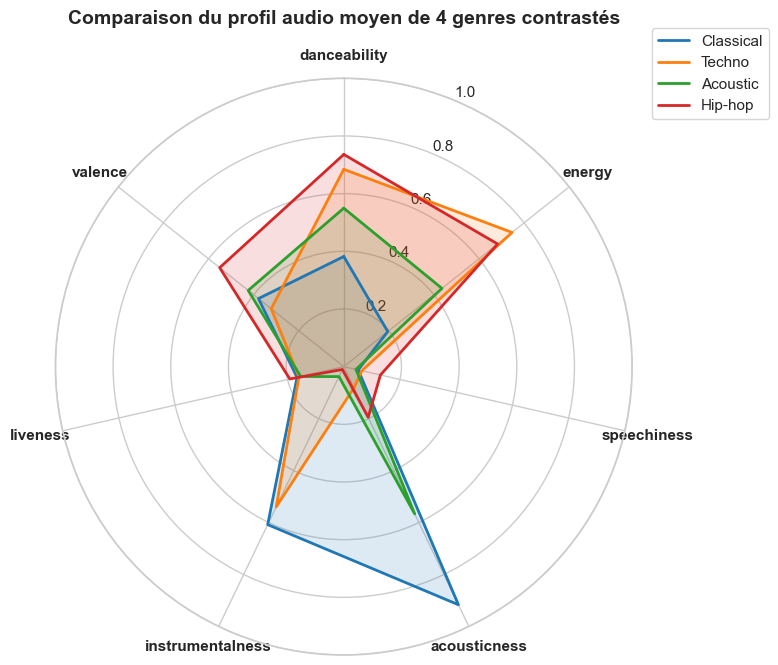

In [17]:
# Sélection des variables audio bornées entre 0 et 1 pour une échelle homogène sur le radar
features_radar = [
    'danceability', 'energy', 'speechiness', 
    'acousticness', 'instrumentalness', 'liveness', 'valence'
]

# Sélection de 4 genres très contrastés
genres_cibles = ['classical', 'techno', 'acoustic', 'hip-hop']

# Calcul du profil moyen sur df_genres avec un tableau de 4 lignes (genre) et 7 colonnes (mean)
profil_genres = df_genres[df_genres['track_genre'].isin(genres_cibles)]\
    .groupby('track_genre')[features_radar].mean()

display(profil_genres.round(3))

# Préparation des angles du Radar Chart
nb_vars = len(features_radar)
angles = np.linspace(0, 2 * np.pi, nb_vars, endpoint=False).tolist()
angles += angles[:1]  # Fermeture du polygone

# Création de la figure polaire
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

couleurs = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

for idx, genre in enumerate(genres_cibles):
    valeurs = profil_genres.loc[genre].tolist()
    valeurs += valeurs[:1]  # Fermeture du polygone
    ax.plot(angles, valeurs, linewidth=2, linestyle='solid', label=genre.capitalize(), color=couleurs[idx])
    ax.fill(angles, valeurs, color=couleurs[idx], alpha=0.15)

# Configuration des axes et légendes
ax.set_theta_offset(np.pi / 2)
ax.set_theta_direction(-1)
ax.set_thetagrids(np.degrees(angles[:-1]), features_radar, fontsize=11, fontweight='bold')
ax.set_ylim(0, 1)
plt.title("Comparaison du profil audio moyen de 4 genres contrastés", size=14, fontweight='bold', y=1.08)
plt.legend(loc='upper right', bbox_to_anchor=(1.25, 1.1))
plt.tight_layout()
plt.show()

> **Analyse et commentaire du profil audio des genres :**
>  
> 1. **Le profil de la Techno (Orange) :** 
>    - Se distingue par une énergie (*energy*), une dansabilité (*danceability*) et une instrumentalisation (*instrumentalness*) élevées, tout en s'effondrant sur l'acoustique (*acousticness* proche de 0). C'est le reflet parfait d'une musique synthétique, rythmée et taillée pour le clubbing.
> 
> 2. **Le profil du Classique (Bleu) :** 
>    - Présente une configuration unique en « pic » : une instrumentalisation (*instrumentalness*) élevée et une acoustique (*acousticness*) maximale, associées à une énergie et une dansabilité très faibles. La variable speechiness est nulle et le modèle capte bien la nature purement instrumentale et non amplifiée de la musique classique.
> 
> 3. **Le profil du Hip-Hop (Rouge) :** 
>    - Affiche les scores les plus élevés en dansabilité et une énergie soutenue, ce qui correspond aux codes structurels du genre.
> 
> 4. **Le profil Acoustic (Vert) :** 
>    - Occupe une position intermédiaire équilibrée, avec une forte composante acoustique mais un profil rythmique plus modéré que la techno ou le hip-hop.

In [18]:
# Détection des valeurs aberrantes par la méthode IQR sur duration_s, tempo et loudness
variables_iqr = ['duration_s', 'tempo', 'loudness']
rapport_iqr = []

for col in variables_iqr:
    Q1 = df_tracks[col].quantile(0.25)
    Q3 = df_tracks[col].quantile(0.75)
    IQR = Q3 - Q1
    borne_inf = Q1 - 1.5 * IQR
    borne_sup = Q3 + 1.5 * IQR
    
    # Comptage des valeurs hors bornes
    outliers = df_tracks[(df_tracks[col] < borne_inf) | (df_tracks[col] > borne_sup)]
    pct_outliers = (len(outliers) / len(df_tracks)) * 100
    
    rapport_iqr.append({
        'Variable': col,
        'Q1': round(Q1, 2),
        'Q3': round(Q3, 2),
        'IQR': round(IQR, 2),
        'Borne Inf': round(borne_inf, 2),
        'Borne Sup': round(borne_sup, 2),
        'Nb Outliers': len(outliers),
        '% du catalogue': round(pct_outliers, 2)
    })

df_iqr = pd.DataFrame(rapport_iqr)
display(df_iqr)

,Variable,Q1,Q3,IQR,Borne Inf,Borne Sup,Nb Outliers,% du catalogue
0,duration_s,173.04,264.29,91.25,36.16,401.17,4226,4.71
1,tempo,99.26,140.08,40.81,38.04,201.30,514,0.57
2,loudness,-10.32,-5.11,5.21,-18.14,2.71,5026,5.60


### 2.6. Synthèse et gestion des valeurs aberrantes (IQR)

- **Observations :** La méthode de l'écart interquartile (IQR) met en évidence des valeurs situées hors des intervalles de normalité statistique :
  - Sur la **durée (`duration_s`)**, 4,71 % du catalogue (4 226 pistes) dépasse la borne supérieure de 6 minutes 40, reflétant des morceaux de longue durée (live, versions longues).
  - Sur le **tempo (`tempo`)**, une distribution très homogène avec seulement 0,57 % de valeurs atypiques.
  - Sur le **volume (`loudness`)**, 5,60 % de pistes sortent de l'intervalle [-18,14 dB ; +2,71 dB], traduisant des dynamiques de mixage très variées (morceaux très compressés ou à l'inverse très peu amplifiés).

- **Décision :** Ces valeurs ne constituent pas des erreurs de saisie technique, mais traduisent la diversité réelle des formats présents dans le catalogue brut. Nous faisons le choix de les conserver intégralement dans nos DataFrames afin de ne pas artificialiser la réalité du catalogue.

## 3. Tests statistiques d'hypothèses

Dans cette section, nous répondons aux trois interrogations en mobilisant des tests statistiques formels (définition des hypothèses $H_0 / H_1$, choix du seuil $\alpha = 0,05$, calcul de la p-value et de la taille d'effet).

Questions : 

    - Est-ce que les caractéristiques audio sont liées entre elles (par exemple energy et loudness) ?
    - Est-ce que la popularité diffère vraiment selon le genre ?
    - Est-ce que le contenu explicite dépend du genre ?

### 3.1. Relations entre caractéristiques audio (Quantitatif / Quantitatif)

**Question 1 :** *« Est-ce que les caractéristiques audio sont liées entre elles (par exemple energy et loudness) ? »*

#### Choix du test statistique :
- **Variables analysées :** Variables continues (`energy` et `loudness`), issues du catalogue dédupliqué `df_tracks` ($N = 89\ 740$).
- **Conditions de validité :** L'analyse des formes de distribution réalisée à l'étape 2 a mis en évidence une asymétrie marquée et un kurtosis leptocurtique élevé ($Kurtosis = 5{,}47$ pour `loudness`), écartant l'hypothèse de normalité bivariée requise par le test de Pearson.
- **Décision :** Nous appliquons le test de corrélation des rangs de Spearman ($r_s$ ou $\rho$), test non paramétrique évaluant toute relation monotone. Le coefficient de Pearson ($r$) est conservé en parallèle à titre comparatif pour mesurer l'intensité linéaire.

#### Hypothèses du test :
- **Hypothèse nulle ($H_0$) :** Il n'existe aucune relation entre l'énergie et le volume sonore ($r_s = 0$).
- **Hypothèse alternative ($H_1$) :** Il existe une corrélation significative ($r_s \neq 0$).
- **Seuil critique :** $\alpha = 0{,}05$.

In [19]:
# Sélection des caractéristiques audio
audio_features = [
    'danceability', 'energy', 'loudness', 'speechiness', 
    'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo'
]

# Calcul des matrices de corrélation
corr_spearman = df_tracks[audio_features].corr(method='spearman')

# Test sur le couple Energy / Loudness
x_energy = df_tracks['energy']
y_loudness = df_tracks['loudness']

spearman_stat, spearman_p = stats.spearmanr(x_energy, y_loudness)
pearson_stat, pearson_p = stats.pearsonr(x_energy, y_loudness)

print("RÉSULTATS DU TEST STATISTIQUE (Energy vs Loudness)")
print(f"Coefficient de Spearman (r_s) : {spearman_stat:.4f}")
print(f"p-value (Spearman)           : {spearman_p}")
print(f"Coefficient de Pearson (r)    : {pearson_stat:.4f} (p-value : {pearson_p})")
print(f"p-value (Pearson) : {pearson_p}")

if spearman_p < 0.05:
    print("\nDécision : p-value < 0.05 -> Rejet de H0 au seuil alpha = 5%.")
else:
    print("\nDécision : p-value >= 0.05 -> Non-rejet de H0.")

RÉSULTATS DU TEST STATISTIQUE (Energy vs Loudness)
Coefficient de Spearman (r_s) : 0.7532
p-value (Spearman)           : 0.0
Coefficient de Pearson (r)    : 0.7588 (p-value : 0.0)
p-value (Pearson) : 0.0

Décision : p-value < 0.05 -> Rejet de H0 au seuil alpha = 5%.


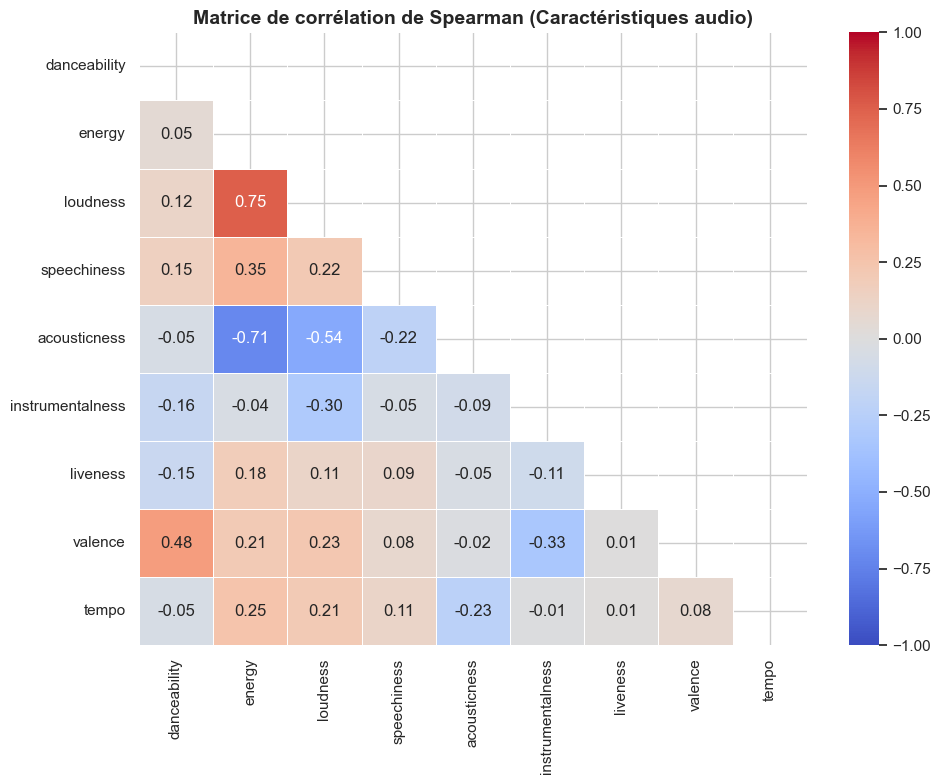

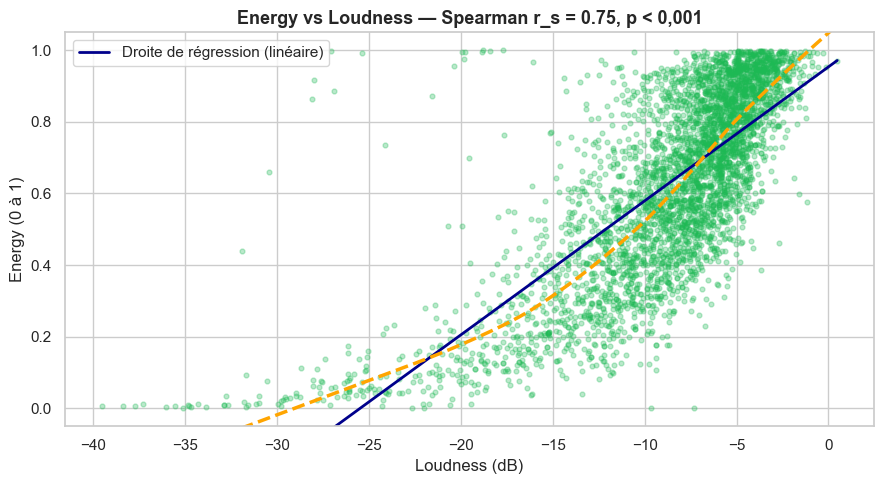

In [20]:
# Affichage graphique 1 : Matrice de corrélation (Heatmap)
plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))
sns.heatmap(
    corr_spearman, 
    mask=mask,
    annot=True, 
    fmt=".2f", 
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5
)
plt.title("Matrice de corrélation de Spearman (Caractéristiques audio)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Affichage graphique 2 : Nuage de points Energy vs Loudness avec tendance non-linéaire (LOWESS)
sample_df = df_tracks.sample(4000, random_state=42)

fig, ax = plt.subplots(figsize=(9, 5))

sns.regplot(data=sample_df, x='loudness', y='energy', ax=ax, ci=None,
            scatter_kws={'alpha': 0.3, 'color': '#1DB954', 's': 12},
            line_kws={'color': 'darkblue', 'linewidth': 2,
                      'label': 'Droite de régression (linéaire)'})
# Tendance réelle, non linéaire
sns.regplot(data=sample_df, x='loudness', y='energy', ax=ax, lowess=True, scatter=False,
            line_kws={'color': 'orange', 'linewidth': 2.5, 'linestyle': '--',
                      'label': 'Tendance observée (LOWESS)'})

ax.set_ylim(-0.05, 1.05)   # energy est bornée entre 0 et 1
ax.set_title(f"Energy vs Loudness — Spearman r_s = {spearman_stat:.2f}, p < 0,001",
             fontsize=13, fontweight='bold')
ax.set_xlabel('Loudness (dB)')
ax.set_ylabel('Energy (0 à 1)')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

#### Conclusion première hypothèse :
1. **Liaison entre Energy et Loudness :**  
   Le test de Spearman révèle une corrélation positive très forte ($r_s = 0{,}753$) avec une $p\text{-value} < 10^{-15}$. On rejette $H_0$. Plus un morceau est masterisé à un volume moyen élevé (valeur en dB proche de 0), plus son intensité énergétique perçue est forte et cela de manière exponentielle.
   Bien que la relation soit non-linéaire, le coefficient de Pearson ($r = 0{,}7588$) reste très élevé et proche de Spearman, confirmant la robustesse globale de cette liaison monotone. 
2. **Comportement des autres caractéristiques :**  
   - `energy` et `acousticness` s'opposent très fortement ($r_s = -0{,}71$) : les titres acoustiques ont structurellement une énergie sonore bien plus basse.
   - `danceability` et `valence` présentent un lien positif modéré ($r_s = 0{,}48$) : les morceaux faits pour danser véhiculent une humeur musicale plus positive.
3. **Conclusion métier :**  
  Les ingénieurs du son et les labels masterisent quasi systématiquement les morceaux énergiques à un volume perçu élevé. Pour la stratégie de MeloWave, cela signifie que si le comité éditorial souhaite booster les playlists "Workout" ou "Energy", la sélection de morceaux à forte intensité sonore garantira ce rendu perçu "punchy", sans avoir à chercher des réglages audio atypiques.

### 3.2. Différence de popularité selon le genre (Quantitatif vs Qualitatif)

**Question 2 :** *« Est-ce que la popularité diffère vraiment selon le genre ? »*

#### Choix du test statistique :
- **Variables analysées :** Une variable quantitative (`popularity`) avec une variable qualitative (`track_genre`, 114 genres musicaux).
- **Table de travail :** Nous utilisons `df_genres` ($N = 113\ 549$), car chaque ligne représente le rattachement d'un titre à son univers musical.
- **Conditions de validité :** La distribution de la popularité est asymétrique avec un pic d'écoutes nulles (10,53 %). L'hypothèse de normalité intragroupe nécessaire pour une ANOVA à un facteur n'étant pas respectée, nous retenons le test non paramétrique de Kruskal-Wallis.

#### Hypothèses du test :
- **Hypothèse nulle ($H_0$) :** Les distributions (et médianes) de popularité sont identiques pour tous les genres musicaux.
- **Hypothèse alternative ($H_1$) :** Au moins un genre musical a une distribution de popularité significativement différente des autres.
- **Seuil critique :** $\alpha = 0{,}05$.

In [21]:
# Test de normalité de Shapiro-Wilk sur un échantillon représentatif
sample_shapiro = df_tracks['popularity'].sample(2000, random_state=42)
shapiro_stat, shapiro_p = stats.shapiro(sample_shapiro)

print("TEST DE NORMALITÉ DE SHAPIRO-WILK (Popularité)")
print(f"Statistique W : {shapiro_stat:.4f}")
print(f"p-value      : {shapiro_p}")

if shapiro_p < 0.05:
    print("\nDécision : p-value < 0.05 -> Rejet de l'hypothèse de normalité.")
else:
    print("\nDécision : p-value >= 0.05 -> Normalité non rejetée.")

TEST DE NORMALITÉ DE SHAPIRO-WILK (Popularité)
Statistique W : 0.9736
p-value      : 1.0092666308227647e-18

Décision : p-value < 0.05 -> Rejet de l'hypothèse de normalité.


In [22]:
# Préparation des groupes de popularité par genre
genre_groups = [group['popularity'].values for _, group in df_genres.groupby('track_genre')]

# Exécution du test de Kruskal-Wallis
kw_stat, kw_p = stats.kruskal(*genre_groups)

print("TEST DE KRUSKAL-WALLIS (Popularité selon le genre)")
print(f"Statistique H de Kruskal-Wallis : {kw_stat:.4f}")
print(f"p-value : {kw_p}")

if kw_p < 0.05:
    print("\nDécision : p-value < 0.05 -> Rejet de H0 au seuil alpha = 5%.")
else:
    print("\nDécision : p-value >= 0.05 -> Non-rejet de H0.")

TEST DE KRUSKAL-WALLIS (Popularité selon le genre)
Statistique H de Kruskal-Wallis : 30955.2571
p-value : 0.0

Décision : p-value < 0.05 -> Rejet de H0 au seuil alpha = 5%.


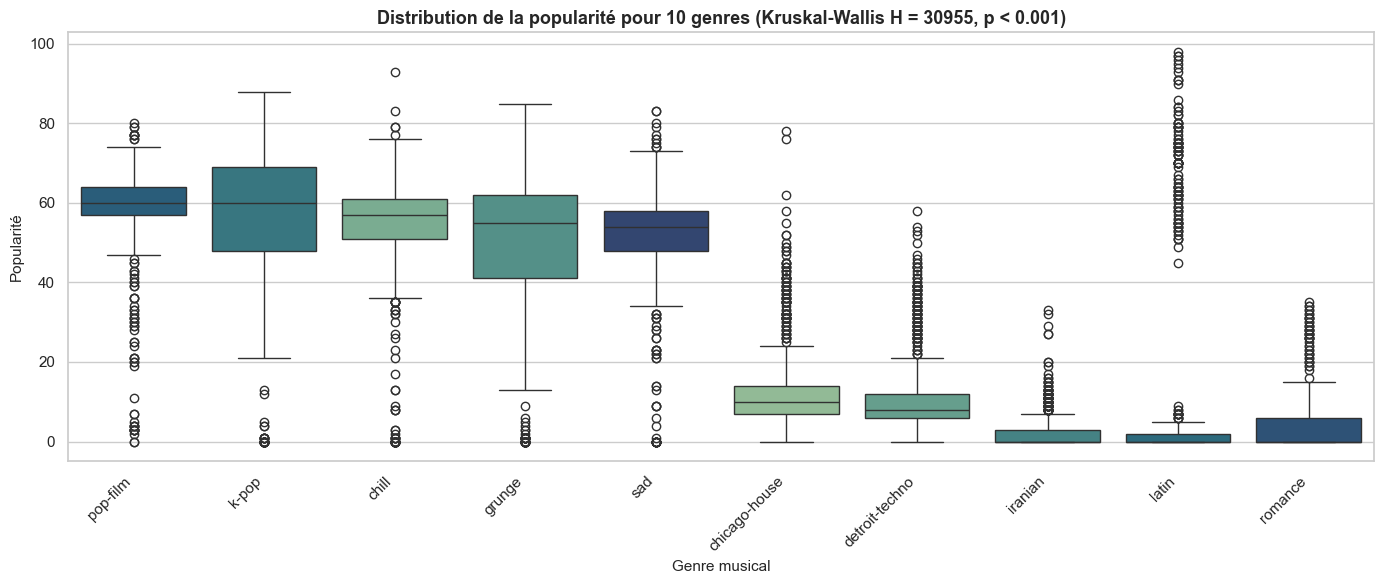

In [23]:
# Pour illustrer le test de façon lisible, nous sélectionnons les 5 genres les plus populaires et les 5 moins populaires
top_5_genres = df_genres.groupby('track_genre')['popularity'].mean().nlargest(5).index.tolist()
bottom_5_genres = df_genres.groupby('track_genre')['popularity'].mean().nsmallest(5).index.tolist()
selected_genres = top_5_genres + bottom_5_genres

df_sub_genres = df_genres[df_genres['track_genre'].isin(selected_genres)].copy()

# Ordre d'affichage trié par popularité médiane décroissante
order_genres = df_sub_genres.groupby('track_genre')['popularity'].median().sort_values(ascending=False).index

plt.figure(figsize=(14, 6))
sns.boxplot(
    data=df_sub_genres, 
    x='track_genre', 
    y='popularity', 
    order=order_genres,
    hue='track_genre',
    palette='crest',
    legend=False         
)
plt.title(f"Distribution de la popularité pour 10 genres (Kruskal-Wallis H = {kw_stat:.0f}, p < 0.001)", fontsize=13, fontweight='bold')
plt.xlabel("Genre musical", fontsize=11)
plt.ylabel("Popularité", fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

#### Conclusion seconde hypothèse :
1. **Validation statistique de la disparité entre genres :**  
   Le test de Kruskal-Wallis affiche une statistique $H = 30\ 955{,}26$ avec une $p\text{-value} = p < 10^{-15}$. On rejette l'hypothèse nulle $H_0$. La popularité ne se distribue absolument pas de façon homogène selon les genres musicaux.
2. **Explication des comportements :**  
   - Les genres contemporains axés sur le streaming de masse et les réseaux sociaux (`pop-film`, `k-pop`, `chill`, `sad`) affichent des médianes de popularité très élevées (proches de 60/100).
   - À l'inverse, les genres de niche régionale ou très spécifiques (`iranian`, `romance`, `latin`) ont des médianes proches ou égales à 0, concentrant une forte proportion de titres dormants.
3. **Conclusion métier :**  
  La recommandation serait de ne pas traiter le catalogue de la même manière selon les genres ; les acquisitions éditoriales doivent cibler en priorité les genres à fort potentiel de streaming actuel. Nous observons que sur notre graphique, des genres comme latin concentrent une immense concentration de tubes à très forte popularité.

### 3.3. Dépendance du contenu explicite selon le genre (Qualitatif vs Qualitatif)

**Question 3 :** *« Est-ce que le contenu explicite dépend du genre ? »*

#### Choix du test statistique :
- **Variables analysées :** Deux variables qualitatives : track_genre et explicit (variable booléenne indiquant la présence de paroles explicites)
- **Table de travail :** Nous utilisons df_genres ($N = 113\ 549$), car chaque ligne représente le rattachement d'un titre à son genre musical.
- **Conditions de validité :** S'agissant du croisement de deux variables catégorielles, le test statistique de référence est le test du $χ_2$. 

#### Hypothèses du test :
- **Hypothèse nulle ($H_0$) :** Le contenu explicite et le genre musical sont indépendants (la proportion de morceaux explicites est répartie de manière homogène entre les genres).
- **Hypothèse alternative ($H_1$) :** Il existe une dépendance significative entre le genre musical et le contenu explicite.
- **Seuil critique :** $\alpha = 0{,}05$.

In [24]:
# Création de la table de contingence
contingency_table = pd.crosstab(df_genres['track_genre'], df_genres['explicit'])

# Exécution du test du Chi-2 d'indépendance
chi2_stat, chi2_p, dof, expected = stats.chi2_contingency(contingency_table)

print("TEST DU CHI-2")
print(f"Statistique du CHI-2 : {chi2_stat:.2f}")
print(f"Degrés de liberté    : {dof}")
print(f"p-value              : {chi2_p}")

if chi2_p < 0.05:
    print("\nDécision : p-value < 0.05 -> Rejet de H0.")
else:
    print("\nDécision : p-value >= 0.05 -> Non-rejet de H0.")



TEST DU CHI-2
Statistique du CHI-2 : 18362.08
Degrés de liberté    : 113
p-value              : 0.0

Décision : p-value < 0.05 -> Rejet de H0.


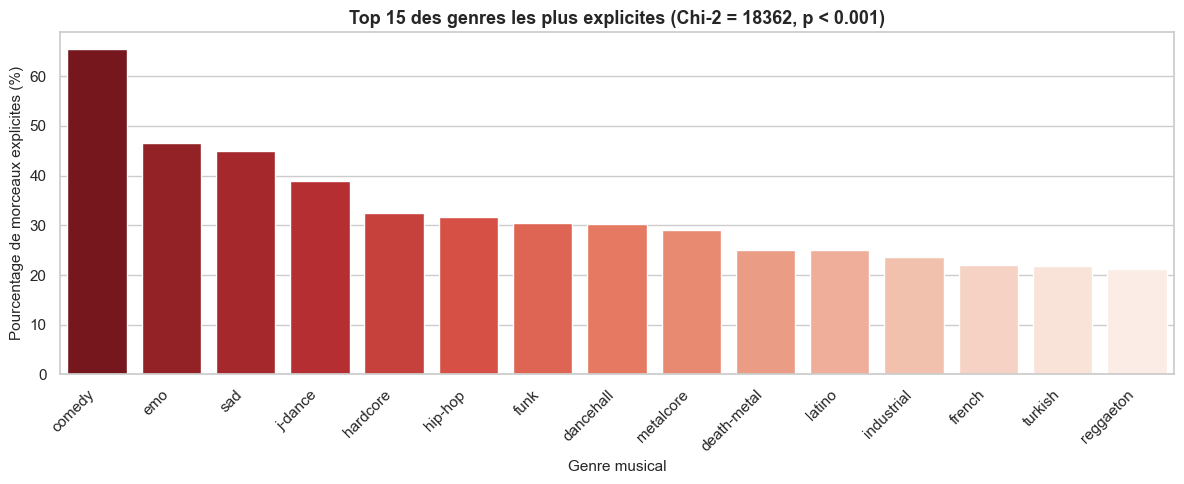

explicit,False,True,% explicite
track_genre,,,
comedy,343,653,65.6
emo,535,465,46.5
sad,550,450,45.0
j-dance,607,386,38.9
hardcore,674,325,32.5
...,...,...,...
honky-tonk,981,0,0.0
study,998,0,0.0
sleep,1000,0,0.0


In [26]:
# Visualisation graphique : Top 15 des genres ayant la plus forte proportion de morceaux explicites
df_genres['explicit_int'] = df_genres['explicit'].astype(int)
explicit_prop = df_genres.groupby('track_genre')['explicit_int'].mean().sort_values(ascending=False).head(15) * 100

plt.figure(figsize=(12, 5))
sns.barplot(
    x=explicit_prop.index, 
    y=explicit_prop.values, 
    hue=explicit_prop.index,
    palette='Reds_r',
    legend=False
)
plt.title(f"Top 15 des genres les plus explicites (Chi-2 = {chi2_stat:.0f}, p < 0.001)", fontsize=13, fontweight='bold')
plt.xlabel("Genre musical", fontsize=11)
plt.ylabel("Pourcentage de morceaux explicites (%)", fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

#affichage du tableau de contingence
table_affichee = contingency_table.copy()
table_affichee['% explicite'] = (table_affichee[True] / table_affichee.sum(axis=1) * 100).round(1)
display(table_affichee.sort_values('% explicite', ascending=False))

#### Conclusion troisième hypothèse :
1. **Validation statistique de la dépendance :**  
   Le test du Chi-2 d'indépendance donne une statistique $\chi^2 \approx 18\,362$ avec une $p\text{-value} < 10^{-15}$. On rejette l'hypothèse nulle $H_0$. Le contenu explicite n'est pas réparti au hasard : il est fortement dépendant du genre musical.
2. **Constats des comportements :**  
   Le contenu explicite est concentré dans comedy (65,6 %), emo (46,5 %), sad (45,0 %), j-dance (38,9 %) et hardcore (32,5 %), absent de sleep, tango, study, honky-tonk et world-music, alors que seuls 8,6 % des morceaux du catalogue sont explicites.

Il est intéressant de noter que sur Spotify, les albums de sketchs et d'humoristes sont systématiquement taggés comme explicites en raison du langage parlé ou même des blagues.

3. **Conclusion métier :**  
   Lors de la création de playlists thématiques ou grand public, le filtrage du contenu explicite doit être automatisé et géré en amont pour éviter les erreurs de ciblage éditorial. (en filtrant explicit == False)